# 04 — LSTM : prévision de la production solaire
Entrée : `data/processed/solar_hourly.csv` (produit par le notebook 02).
Étapes : features → découpage temporel → fenêtres glissantes → LSTM → comparaison avec la persistance → sauvegarde.
Le code du modèle est dans `src/models/lstm_solar.py`.

In [1]:
import sys, os
sys.path.append(os.path.abspath(".."))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.models.lstm_solar import (SolarLSTM, add_time_features, split_chronological,
                                   set_seed, compute_metrics)
set_seed(42)

## 1. Chargement et features

In [2]:
df = pd.read_csv("../data/processed/solar_hourly.csv", index_col=0, parse_dates=True)
df = add_time_features(df)
train, val, test = split_chronological(df, 0.70, 0.15)
print(len(train), len(val), len(test))
df.head()

1964 421 421


,Radiation,Temperature,Pressure,Humidity,WindDirection,Speed,hour_sin,hour_cos,doy_sin,doy_cos
timestamp,,,,,,,,,,
2016-09-01 00:00:00,2.288750,51.125000,30.430000,103.000000,109.837500,8.857500,0.000000,1.000000,-0.878637,-0.477489
2016-09-01 01:00:00,2.943333,51.500000,30.417500,103.000000,121.345833,5.246667,0.258819,0.965926,-0.878637,-0.477489
2016-09-01 02:00:00,2.733333,51.000000,30.404167,103.000000,136.402500,9.653333,0.500000,0.866025,-0.878637,-0.477489
2016-09-01 03:00:00,2.344545,50.818182,30.400000,102.636364,89.257273,5.520909,0.707107,0.707107,-0.878637,-0.477489
2016-09-01 04:00:00,2.607500,49.083333,30.407500,102.000000,118.165833,7.965833,0.866025,0.500000,-0.878637,-0.477489


## 2. Paramètres
`WINDOW` = heures passées en entrée ; `HORIZON` = heures à prévoir (1 = prochaine heure, 24 = journée suivante).

In [3]:
WINDOW  = 24
HORIZON = 1
model = SolarLSTM(window=WINDOW, horizon=HORIZON, units=(64, 32), dropout=0.2, learning_rate=1e-3)
model.build().summary()

Model: "solar_lstm"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 24, 64)         │        18,944 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 24, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 31,393 (122.63 KB)

 Trainable params: 31,393 (122.63 KB)

 Non-trainable params: 0 (0.00 B)

## 3. Entraînement

In [6]:
history = model.fit(train, val, epochs=60, batch_size=64, patience=8)

Epoch 1/60
31/31 ━━━━━━━━━━━━━━━━━━━━ 11s 81ms/step - loss: 0.0547 - mae: 0.1842 - val_loss: 0.0450 - val_mae: 0.1800 - learning_rate: 0.0010
Epoch 2/60
31/31 ━━━━━━━━━━━━━━━━━━━━ 1s 44ms/step - loss: 0.0314 - mae: 0.1408 - val_loss: 0.0270 - val_mae: 0.1296 - learning_rate: 0.0010
Epoch 3/60
31/31 ━━━━━━━━━━━━━━━━━━━━ 1s 35ms/step - loss: 0.0282 - mae: 0.1323 - val_loss: 0.0227 - val_mae: 0.1173 - learning_rate: 0.0010
Epoch 4/60
31/31 ━━━━━━━━━━━━━━━━━━━━ 1s 33ms/step - loss: 0.0274 - mae: 0.1258 - val_loss: 0.0178 - val_mae: 0.1028 - learning_rate: 0.0010
Epoch 5/60
31/31 ━━━━━━━━━━━━━━━━━━━━ 1s 43ms/step - loss: 0.0246 - mae: 0.1139 - val_loss: 0.0139 - val_mae: 0.0846 - learning_rate: 0.0010
Epoch 6/60
31/31 ━━━━━━━━━━━━━━━━━━━━ 1s 35ms/step - loss: 0.0166 - mae: 0.0918 - val_loss: 0.0132 - val_mae: 0.0789 - learning_rate: 0.0010
Epoch 7/60
31/31 ━━━━━━━━━━━━━━━━━━━━ 1s 32ms/step - loss: 0.0158 - mae: 0.0865 - val_loss: 0.0122 - val_mae: 0.0742 - learning_rate: 0.0010
Epoch 8/60
3

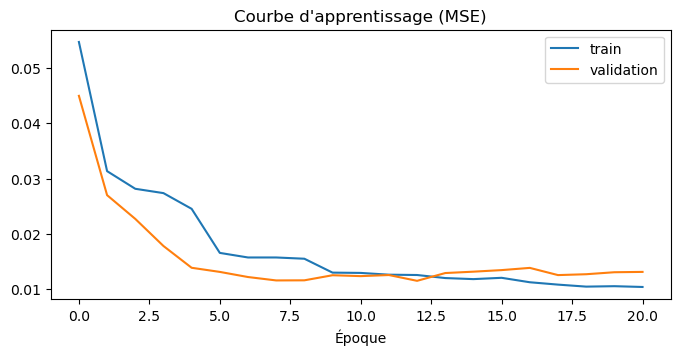

In [7]:
plt.figure(figsize=(8, 3.5))
plt.plot(history.history["loss"], label="train")
plt.plot(history.history["val_loss"], label="validation")
plt.title("Courbe d'apprentissage (MSE)"); plt.xlabel("Époque"); plt.legend(); plt.show()

## 4. Évaluation sur le jeu de test (LSTM vs persistance)

In [8]:
results = pd.DataFrame(model.evaluate(test)).T
results

,MAE,RMSE,R2
LSTM,102.487602,147.838040,0.698843
Persistance,64.473480,117.362266,0.810208


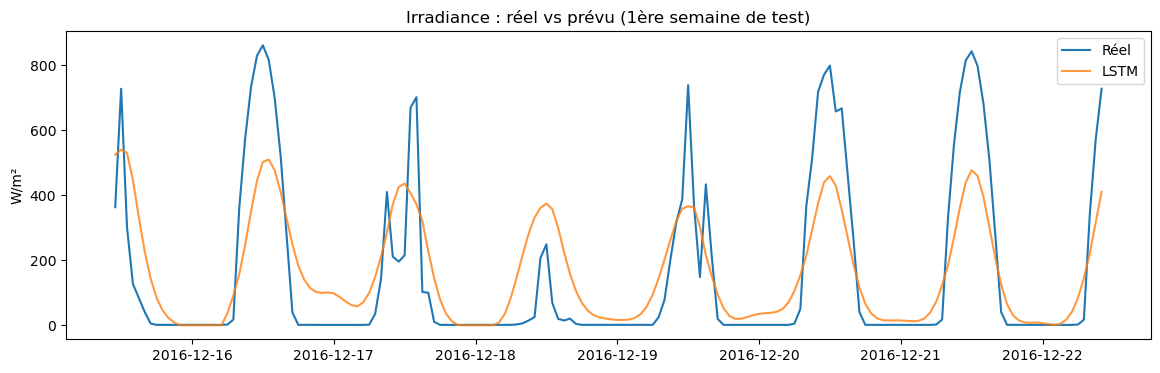

In [9]:
y_true = model.true_values(test)
y_pred = model.predict(test)
idx = model.target_index(test)

N = 24 * 7   # une semaine
plt.figure(figsize=(14, 4))
plt.plot(idx[:N], y_true[:N, 0], label="Réel")
plt.plot(idx[:N], y_pred[:N, 0], label="LSTM", alpha=0.8)
plt.title("Irradiance : réel vs prévu (1ère semaine de test)")
plt.ylabel("W/m²"); plt.legend(); plt.show()

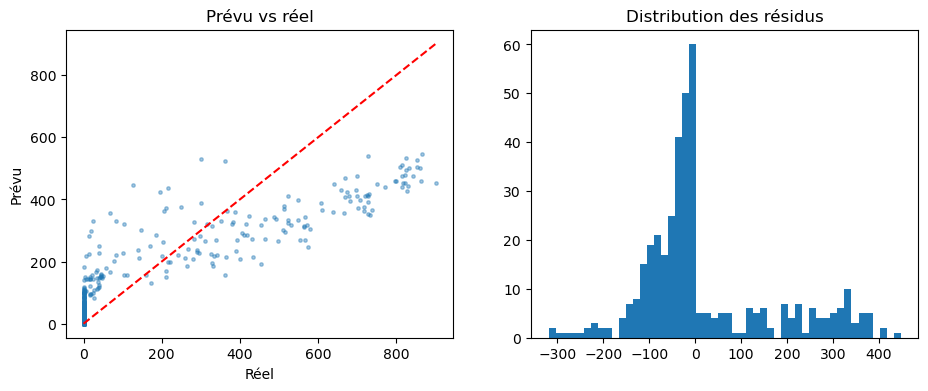

In [10]:
# Nuage de points prédit vs réel + résidus
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].scatter(y_true[:, 0], y_pred[:, 0], s=6, alpha=0.4)
m = max(y_true.max(), y_pred.max()); ax[0].plot([0, m], [0, m], "r--")
ax[0].set_xlabel("Réel"); ax[0].set_ylabel("Prévu"); ax[0].set_title("Prévu vs réel")
ax[1].hist((y_true[:, 0] - y_pred[:, 0]), bins=50)
ax[1].set_title("Distribution des résidus")
plt.show()

## 5. Comparaison de quelques configurations (réglage simple)

In [11]:
configs = [
    {"window": 12, "units": (32,),    "dropout": 0.1},
    {"window": 24, "units": (64, 32), "dropout": 0.2},
    {"window": 48, "units": (64, 32), "dropout": 0.3},
]
rows = []
for c in configs:
    m = SolarLSTM(horizon=HORIZON, **c)
    m.fit(train, val, epochs=40, verbose=0)
    r = m.evaluate(test)["LSTM"]
    rows.append({**{k: str(v) for k, v in c.items()}, **r})
pd.DataFrame(rows)

,window,units,dropout,MAE,RMSE,R2
0,12,"(32,)",0.1,72.914581,113.229510,0.821532
1,24,"(64, 32)",0.2,102.487602,147.838040,0.698843
2,48,"(64, 32)",0.3,113.332527,191.711626,0.500905


## 6. Sauvegarde du modèle

In [ ]:
model.save("../models_saved", "lstm_solar")
loaded = SolarLSTM.load("../models_saved", "lstm_solar")
print(loaded.evaluate(test)["LSTM"])

## Conclusions
- Comparer MAE / RMSE / R² du LSTM à la persistance : le gain justifie (ou non) le modèle.
- La sortie `predict()` (W/m²) sera convertie en production photovoltaïque (surface × rendement) puis envoyée au réseau de tarification (`pipeline.py`).
- Pistes : horizon 24 h, ajout de la météo prévue, GRU, validation croisée temporelle.